In [48]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

In [5]:
data = {
    'Age': [
        'Youth', 'Youth', 'Middle', 'Senior', 'Senior', 'Middle', 'Senior',
        'Youth', 'Youth', 'Senior', 'Senior', 'Middle', 'Youth', 'Middle'],

    'Income': [
        'High', 'High', 'High', 'Medium', 'Low', 'Low', 'Medium',
        'Low', 'Medium', 'Medium', 'Low', 'Medium', 'Medium', 'High' ],

    'Student': [
        'No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes',
        'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No'],

    'CreditRating': [
        'Fair', 'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent',
        'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent',
        'Fair', 'Excellent'],

    'BuysComputer': [
        'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes',
        'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

In [6]:
df=pd.DataFrame(data)

In [7]:
df

,Age,Income,Student,CreditRating,BuysComputer
0,Youth,High,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes
5,Middle,Low,Yes,Excellent,No
6,Senior,Medium,Yes,Excellent,Yes
7,Youth,Low,No,Fair,No
8,Youth,Medium,Yes,Fair,Yes
9,Senior,Medium,Yes,Fair,Yes


In [ ]:
#ENCODE CATEGORICAL -> NUMERIC

In [8]:
from sklearn.preprocessing import LabelEncoder

le = {}  # Create empty dictionary

df_enc = df.copy()  # Keep original data unchanged

for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

In [9]:
df_enc

,Age,Income,Student,CreditRating,BuysComputer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,2,1,0,1
7,2,1,0,1,0
8,2,2,1,1,1
9,1,2,1,1,1


In [13]:
x = df_enc[['Age','Income','Student','CreditRating']]
y = df_enc['BuysComputer']

In [14]:
x

,Age,Income,Student,CreditRating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,2,1,0
7,2,1,0,1
8,2,2,1,1
9,1,2,1,1


In [15]:
model = CategoricalNB() # apply model
model. fit(x,y)# here fit your values

CategoricalNB()

In [35]:
test = [['Youth','Medium','Yes','Fair']]  # testing data

In [36]:
test

[['Youth', 'Medium', 'Yes', 'Fair']]

In [37]:
print("\n--- Prediction ------------------------------")
for t in test:
    row = [[
        le['Age'].transform([t[0]])[0],
        le['Income'].transform([t[1]])[0],
        le['Student'].transform([t[2]])[0],
        le['CreditRating'].transform([t[3]])[0]
    ]]
    pred = le['BuysComputer'].inverse_transform(model.predict(row))[0]
    prob = model.predict_proba(row)[0]
    print(f"Input : Age={t[0]}, Income={t[1]}, Student={t[2]}, CreditRating={t[3]}")
    print(f"Result: Buys Computer -> {pred}")
    print(f"P(No)  = {prob[0]:.4f}")
    print(f"P(Yes) = {prob[1]:.4f}")


--- Prediction ------------------------------
Input : Age=Youth, Income=Medium, Student=Yes, CreditRating=Fair
Result: Buys Computer -> Yes
P(No)  = 0.0672
P(Yes) = 0.9328


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [39]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(x)

print(f"Training Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 85.71%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


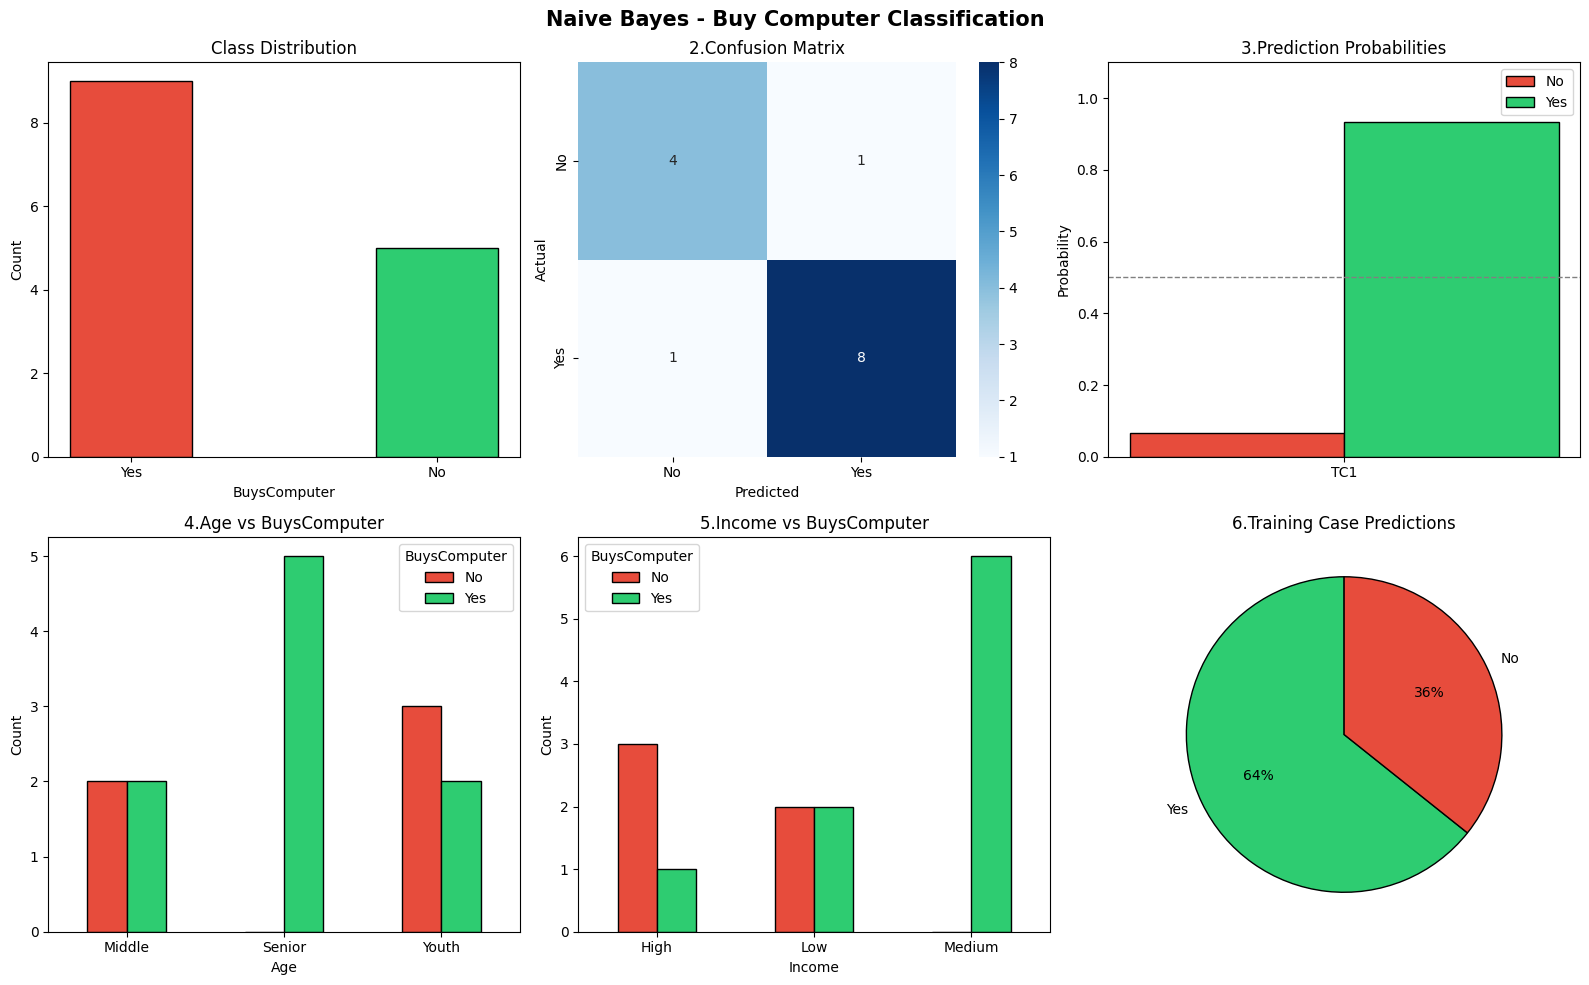

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Prepare prediction probabilities for the test case
probs_no = []
probs_yes = []
for t in test:
    row = [[
        le['Age'].transform([t[0]])[0],
        le['Income'].transform([t[1]])[0],
        le['Student'].transform([t[2]])[0],
        le['CreditRating'].transform([t[3]])[0]
    ]]
    prob = model.predict_proba(row)[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])

# plots-----------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Naive Bayes - Buy Computer Classification", fontsize=15, fontweight='bold')

# 1.Class Distribution
counts = df['BuysComputer'].value_counts()
axes[0,0].bar(counts.index, counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0,0].set_title("Class Distribution")
axes[0,0].set_xlabel("BuysComputer")
axes[0,0].set_ylabel("Count")

# 2.Confusion Matrix
x_features = df_enc[['Age', 'Income', 'Student', 'CreditRating']]
cm = confusion_matrix(y, model.predict(x_features))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[0,1])
axes[0,1].set_title("2.Confusion Matrix")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

# 3.Prediction Probabilities (Grouped Bar)
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_indices = np.arange(len(tc_labels))
width = 0.3
axes[0,2].bar(x_indices - width/2, probs_no, width, label='No', color='#e74c3c', edgecolor='black')
axes[0,2].bar(x_indices + width/2, probs_yes, width, label='Yes', color='#2ecc71', edgecolor='black')
axes[0,2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0,2].set_title("3.Prediction Probabilities")
axes[0,2].set_xticks(x_indices)
axes[0,2].set_xticklabels(tc_labels)
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

# 4.Age vs BuysComputer
age_counts = df.groupby(['Age', 'BuysComputer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1,0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,0].set_title("4.Age vs BuysComputer")
axes[1,0].set_xlabel("Age")
axes[1,0].set_ylabel("Count")
axes[1,0].legend(title='BuysComputer')

# 5.Income vs BuysComputer
income_counts = df.groupby(['Income', 'BuysComputer']).size().unstack(fill_value=0)
income_counts.plot(kind='bar', ax=axes[1,1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,1].set_title("5.Income vs BuysComputer")
axes[1,1].set_xlabel("Income")
axes[1,1].set_ylabel("Count")
axes[1,1].legend(title='BuysComputer')

# 6.pie Chart - Final Predictions
pred_counts = pd.Series(y_pred).value_counts()
# Mapping encoded indices back to labels for pie chart legend
pred_counts.index = le['BuysComputer'].inverse_transform(pred_counts.index)
colors_pie = ['#2ecc71' if label == 'Yes' else '#e74c3c' for label in pred_counts.index]
axes[1,2].pie(pred_counts, labels=pred_counts.index, autopct='%1.0f%%', colors=colors_pie, startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6.Training Case Predictions")
plt.tight_layout()
plt.show()